# EDA 2: Metadata, baselines, resources

## Setup

In [2]:
import json
from pathlib import Path

import kx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from IPython.display import display
except ImportError:
    display = print

kx.use("light", palette="tab10", cmap="blues", figure__figsize=(13, 7))

In [3]:
META_CSV = next(
    p
    for p in (
        Path("data/HAM10000_metadata.csv"),
        Path("data/HAM10000/HAM10000_metadata.csv"),
        Path("../data/HAM10000_metadata.csv"),
        Path("../data/HAM10000/HAM10000_metadata.csv"),
    )
    if p.exists()
)

SEED = 0
CLASSES = ["nv", "mel", "bkl", "bcc", "akiec", "vasc", "df"]
K = len(CLASSES)
N_FOLDS = 5
TEST_FRAC = 0.15
N_BOOT = 100
SPLITS_CSV = None

## 0. Data and split

Lesion-level split (`StratifiedGroupKFold` on `lesion_id`): no lesion can end up in two sets.

In [4]:
df = pd.read_csv(META_CSV)
df["sex"] = df["sex"].fillna("unknown")
df["localization"] = df["localization"].fillna("unknown")

print(f"Images: {len(df):,} | Lesions: {df['lesion_id'].nunique():,} | duplicated image_id: {df['image_id'].duplicated().sum()}")
print(
    f"Lesions with >1 diagnosis: {int((df.groupby('lesion_id')['dx'].nunique() > 1).sum())} | images with missing age: {df['age'].isna().sum()}"
)

if SPLITS_CSV and Path(SPLITS_CSV).exists():
    df = df.merge(pd.read_csv(SPLITS_CSV)[["image_id", "split", "fold"]], on="image_id", how="left")
else:
    outer = StratifiedGroupKFold(n_splits=round(1 / TEST_FRAC), shuffle=True, random_state=SEED)
    _, test_idx = next(outer.split(df, df["dx"], groups=df["lesion_id"]))
    df["split"], df["fold"] = "train", -1
    df.loc[df.index[test_idx], "split"] = "test"
    train_part = df[df["split"] == "train"]
    inner = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for k, (_, val_idx) in enumerate(inner.split(train_part, train_part["dx"], groups=train_part["lesion_id"])):
        df.loc[train_part.index[val_idx], "fold"] = k
    # df[["image_id", "lesion_id", "split", "fold"]].to_csv(OUT / "splits_eda2.csv", index=False)

# leakage checks
assert df.groupby("lesion_id")["split"].nunique().max() == 1
assert df[df["split"] == "train"].groupby("lesion_id")["fold"].nunique().max() == 1

# one row per lesion (age, sex, localization and dataset do not change within a lesion)
lesions = df.sort_values("image_id").drop_duplicates("lesion_id")
df.groupby("split").agg(images=("image_id", "count"), lesions=("lesion_id", "nunique"))

Images: 10,015 | Lesions: 7,470 | duplicated image_id: 0
Lesions with >1 diagnosis: 0 | images with missing age: 57


,images,lesions
split,,
test,1431,1067
train,8584,6403


## 1. Class distribution

Per image


dx,nv,mel,bkl,bcc,akiec,vasc,df,total
all,6705,1113,1099,514,327,142,115,10015
train,5747,954,942,440,281,122,98,8584
test,958,159,157,74,46,20,17,1431
val_fold0,1149,191,188,88,56,25,20,1717
val_fold1,1149,191,188,88,57,25,19,1717
val_fold2,1150,191,189,88,56,24,19,1717
val_fold3,1150,190,189,88,56,24,20,1717
val_fold4,1149,191,188,88,56,24,20,1716


Per lesion


dx,nv,mel,bkl,bcc,akiec,vasc,df,total
all,5403,614,727,327,228,98,73,7470
train,4631,527,623,280,196,84,62,6403
test,772,87,104,47,32,14,11,1067
val_fold0,926,106,124,56,39,17,12,1280
val_fold1,926,106,124,56,40,17,12,1281
val_fold2,927,105,125,56,39,17,12,1281
val_fold3,926,105,125,56,39,17,13,1281
val_fold4,926,105,125,56,39,16,13,1280


{'image': np.float64(58.3), 'lesion': np.float64(74.0)} ==> imbalance ratio (max/min)


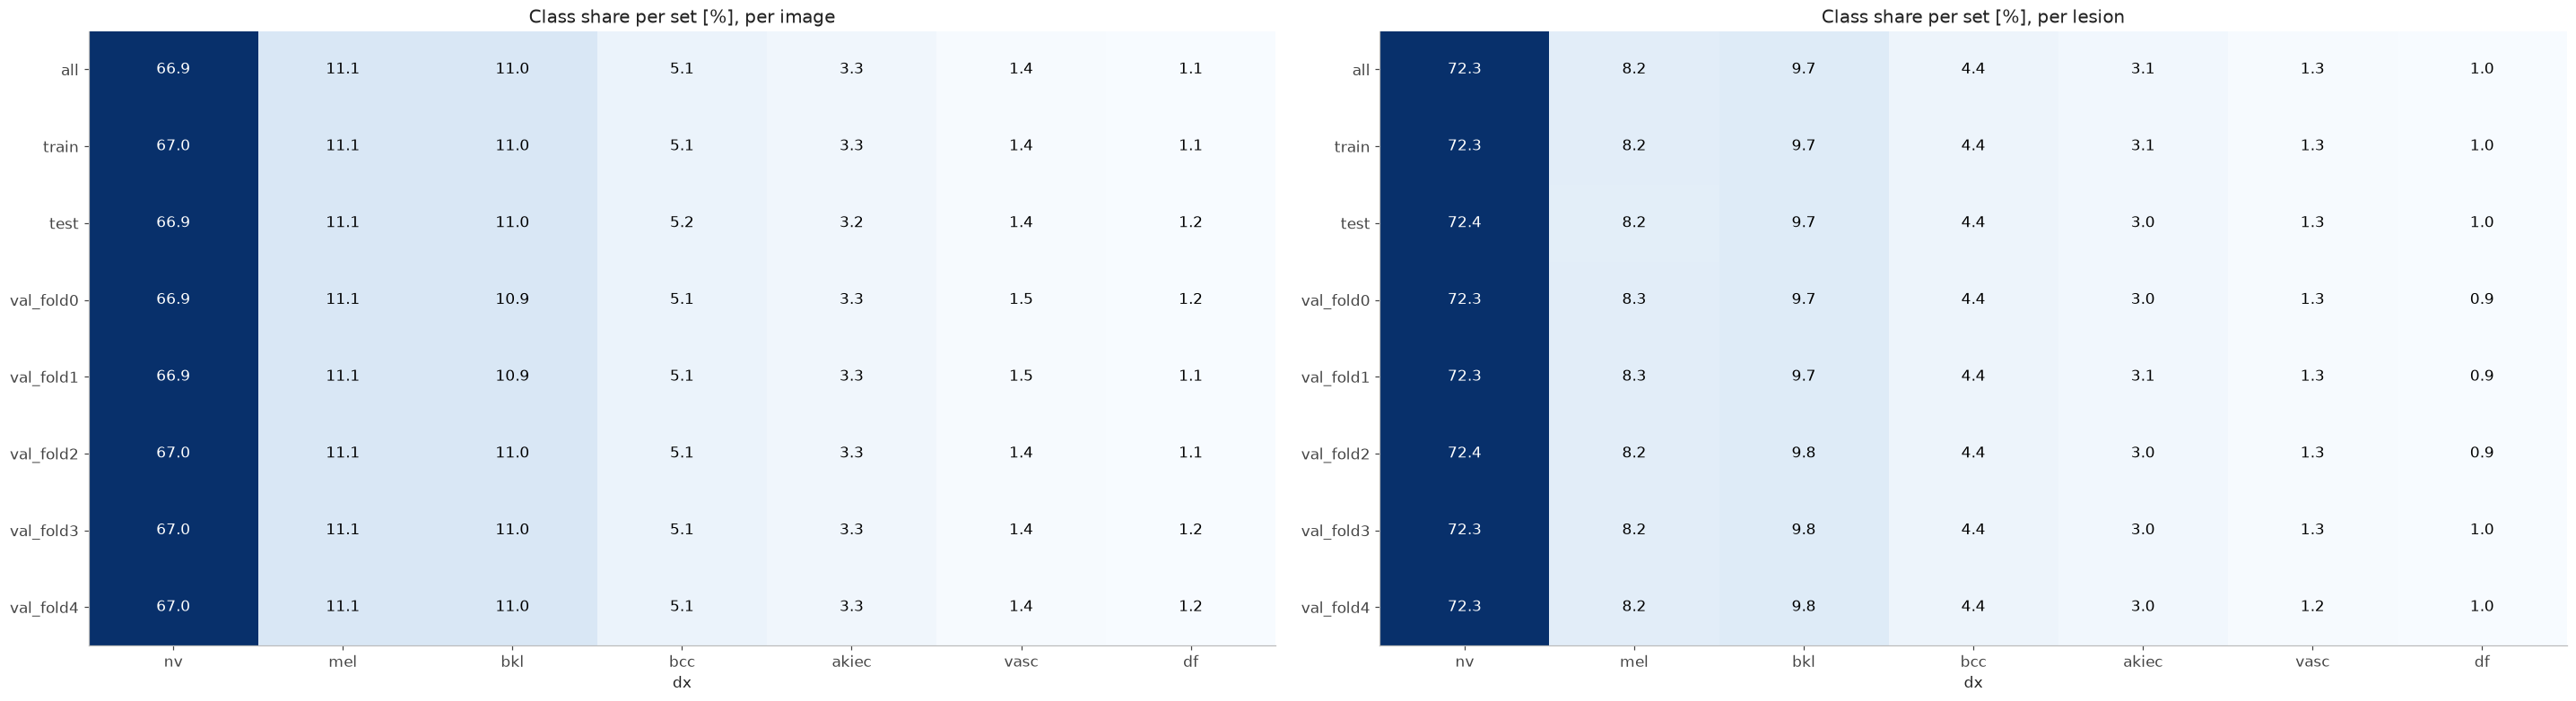

In [5]:
sets = {"all": df, "train": df[df["split"] == "train"], "test": df[df["split"] == "test"]}
sets |= {f"val_fold{k}": df[df["fold"] == k] for k in range(N_FOLDS)}


def class_counts(unit: str) -> pd.DataFrame:
    rows = {name: (d if unit == "image" else d.drop_duplicates("lesion_id"))["dx"].value_counts() for name, d in sets.items()}
    return pd.DataFrame(rows).T.reindex(columns=CLASSES, fill_value=0)


counts = {unit: class_counts(unit) for unit in ("image", "lesion")}
for unit, table in counts.items():
    print(f"Per {unit}")
    display(table.assign(total=table.sum(axis=1)))

for ax, (unit, table) in zip(kx.grid(2, cols=2), counts.items(), strict=True):
    kx.plot(
        table.div(table.sum(axis=1), axis=0) * 100,
        "heat-ann-nocb",
        aspect="auto",
        ax=ax,
        fmt="{:.1f}",
        title=f"Class share per set [%], per {unit}",
    )

print({unit: round(t.loc["all"].max() / t.loc["all"].min(), 1) for unit, t in counts.items()}, "==> imbalance ratio (max/min)")

### Class weights

Computed from training data only, counted per image: for fold k from the train set without validation fold k (plus `full_train`). All schemes are normalised to a mean weight of 1 per sample.

- `inverse`: 1 / n
- `sqrt_inverse`: 1 / sqrt(n)
- `effective_number`: (1 - beta) / (1 - beta^n), beta = 0.999

In [6]:
def class_weights(labels: pd.Series, beta: float = 0.999) -> dict[str, list[float]]:
    n = labels.value_counts().reindex(CLASSES).astype(float)
    raw = {"inverse": 1 / n, "sqrt_inverse": 1 / np.sqrt(n), "effective_number": (1 - beta) / (1 - beta**n)}
    return {name: (w * n.sum() / (w * n).sum()).tolist() for name, w in raw.items()}


train_df = df[df["split"] == "train"]
train_sets = {"full_train": train_df} | {f"fold_{k}": train_df[train_df["fold"] != k] for k in range(N_FOLDS)}
weights = {name: class_weights(d["dx"]) for name, d in train_sets.items()}

config = {
    "classes": CLASSES,
    "counted_on": "train images (per fold: train minus validation fold)",
    "seed": SEED,
    "schemes": {s: {name: weights[name][s] for name in weights} for s in ("inverse", "sqrt_inverse", "effective_number")},
}
# (OUT / "class_weights.json").write_text(json.dumps(config, indent=2))

pd.DataFrame(weights["full_train"], index=CLASSES).round(3).assign(n_train_images=train_df["dx"].value_counts())

,inverse,sqrt_inverse,effective_number,n_train_images
nv,0.213,0.578,0.645,5747
mel,1.285,1.417,1.045,954
bkl,1.302,1.426,1.053,942
bcc,2.787,2.087,1.805,440
akiec,4.364,2.612,2.623,281
vasc,10.052,3.964,5.595,122
df,12.513,4.422,6.883,98


## 2. Metadata by class (per lesion)

Effect sizes: Kruskal-Wallis epsilon-squared for age, bias-corrected Cramer's V for categorical variables. Rule of thumb for V: < 0.1 negligible, < 0.3 small, < 0.5 medium. `dataset` is the image source.

,count,mean,std,min,25%,50%,75%,max
dx,,,,,,,,
nv,5361.0,47.3,14.2,0.0,40.0,45.0,55.0,85.0
mel,613.0,61.3,15.1,5.0,50.0,65.0,70.0,85.0
bkl,718.0,64.4,14.0,0.0,55.0,65.0,75.0,85.0
bcc,327.0,66.9,13.5,20.0,60.0,70.0,77.5,85.0
akiec,228.0,66.6,11.6,30.0,60.0,67.5,75.0,85.0
vasc,98.0,52.5,20.4,0.0,45.0,55.0,70.0,85.0
df,73.0,52.7,13.2,25.0,45.0,55.0,65.0,80.0


dx_type,confocal,consensus,follow_up,histo
dx,,,,
nv,0,332,3704,1367
mel,0,0,0,614
bkl,34,206,0,487
bcc,0,0,0,327
akiec,0,0,0,228
vasc,0,65,0,33
df,0,44,0,29


,test,p,effect
variable,,,
age,Kruskal-Wallis,0.0,0.2113
sex,chi2,0.0,0.0568
localization,chi2,0.0,0.2185
dataset,chi2,0.0,0.3661
dx_type,chi2,0.0,0.4334


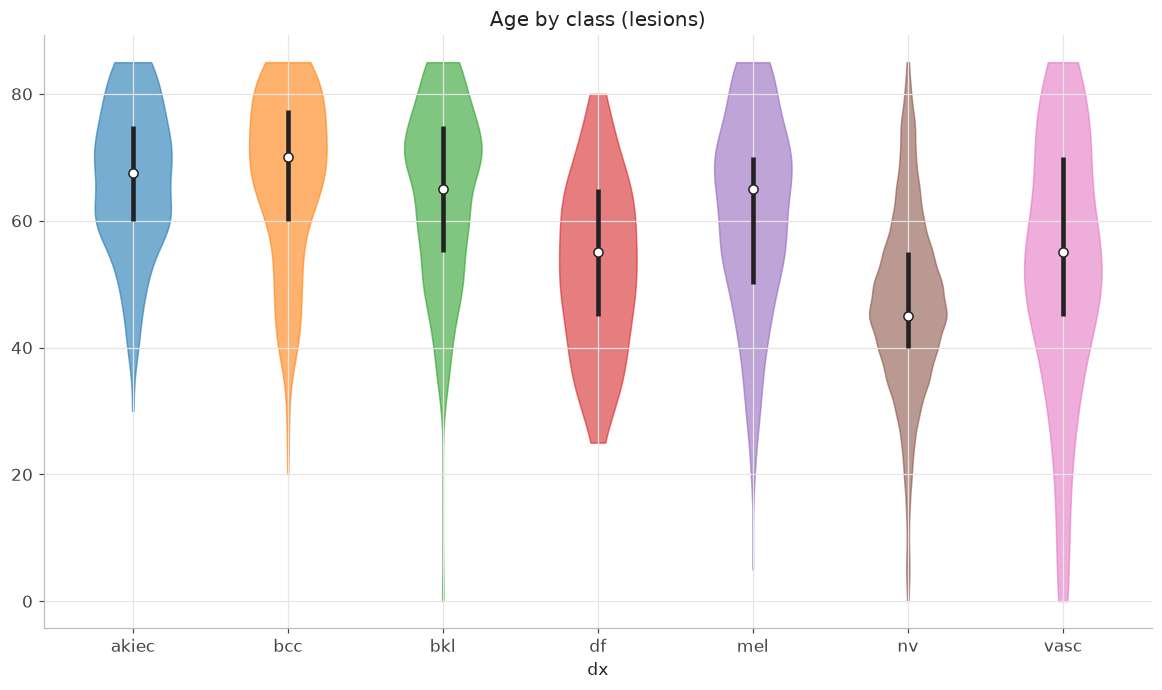

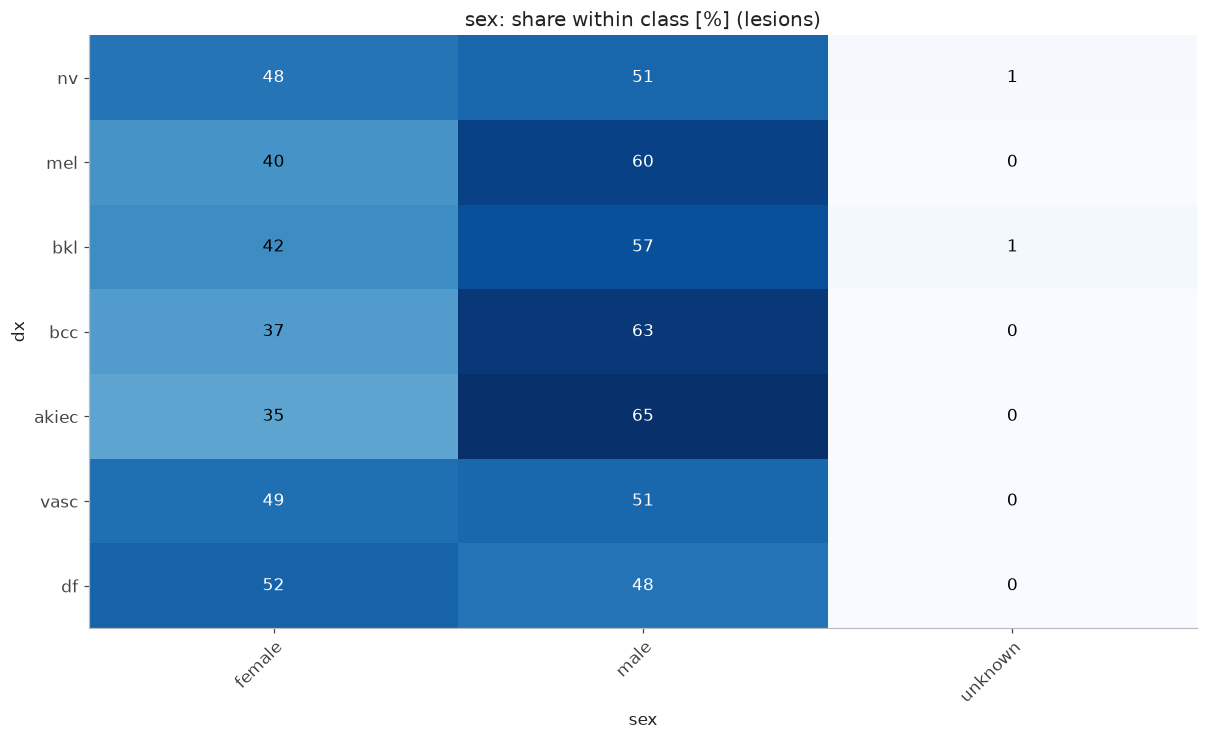

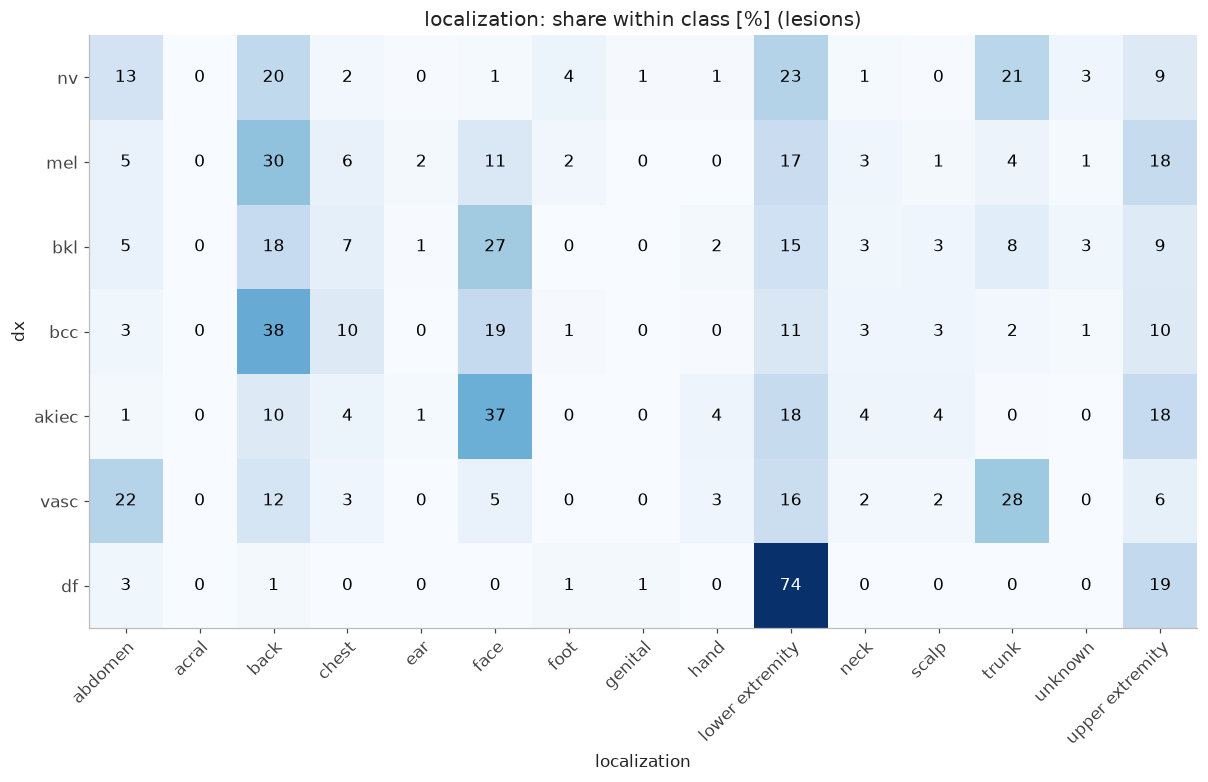

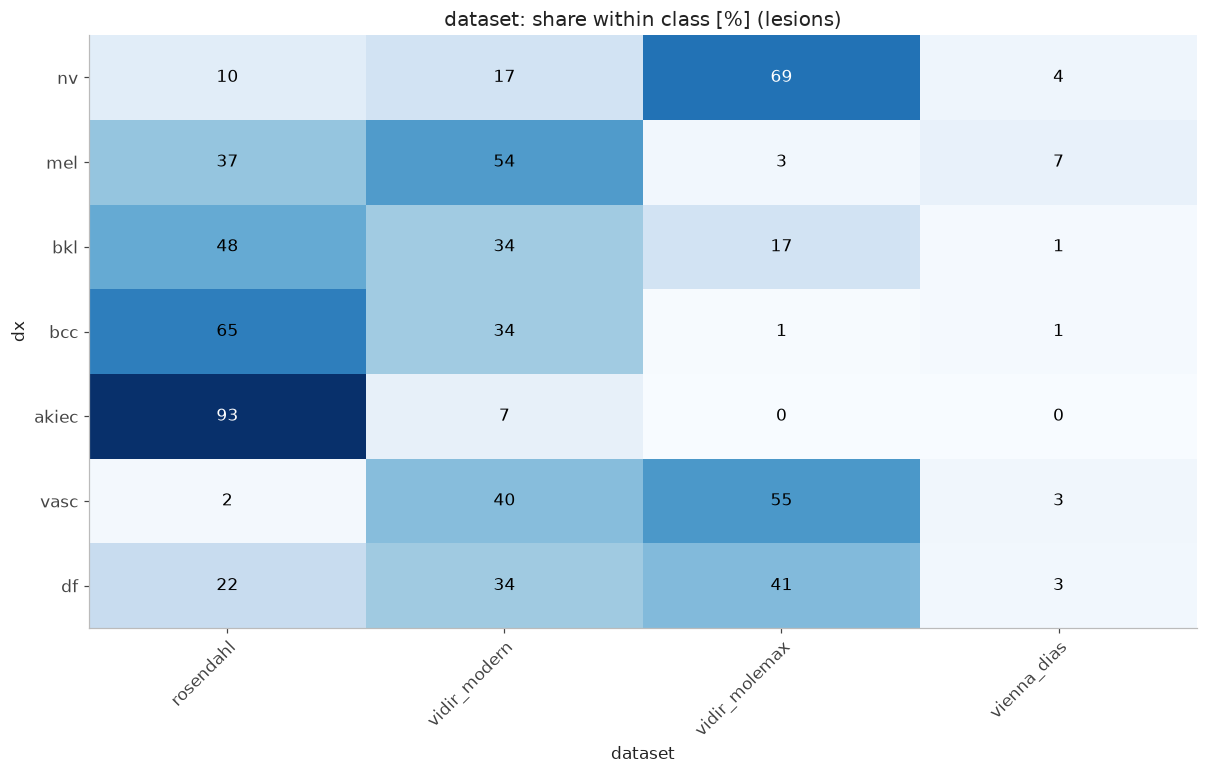

In [7]:
def cramers_v(table: pd.DataFrame) -> float:
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n, (r, c) = table.to_numpy().sum(), table.shape
    phi2 = max(0.0, chi2 / n - (r - 1) * (c - 1) / (n - 1))
    r_corr, c_corr = r - (r - 1) ** 2 / (n - 1), c - (c - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / min(r_corr - 1, c_corr - 1)))


# age
age_groups = [lesions.loc[lesions["dx"] == c, "age"].dropna() for c in CLASSES]
h, p_age = stats.kruskal(*age_groups)
effects = [{"variable": "age", "test": "Kruskal-Wallis", "p": p_age, "effect": (h - K + 1) / (sum(map(len, age_groups)) - K)}]
display(lesions.groupby("dx")["age"].describe().reindex(CLASSES).round(1))

kx.plot(lesions, "age", spec="violin-grid", by="dx", title="Age by class (lesions)")

# sex, localization, dataset
for column in ("sex", "localization", "dataset"):
    table = pd.crosstab(lesions["dx"], lesions[column]).reindex(CLASSES)
    effects.append({"variable": column, "test": "chi2", "p": stats.chi2_contingency(table)[1], "effect": cramers_v(table)})
    kx.plot(
        table.div(table.sum(axis=1), axis=0) * 100,
        "heat-ann-nocb-rot",
        aspect="auto",
        fmt="{:.0f}",
        title=f"{column}: share within class [%] (lesions)",
    )

# dx_type = how the diagnosis was confirmed; tied to the label
table = pd.crosstab(lesions["dx"], lesions["dx_type"]).reindex(CLASSES)
effects.append({"variable": "dx_type", "test": "chi2", "p": stats.chi2_contingency(table)[1], "effect": cramers_v(table)})
display(table)
display(pd.DataFrame(effects).set_index("variable").round(4))

## 3. Train vs test shift

Lesion-level comparison of train and test. A stratified lesion-level split should show a negligible shift.

In [8]:
lesions_train, lesions_test = (lesions[lesions["split"] == s] for s in ("train", "test"))

rows = []
for column in ("dx", "sex", "localization", "dataset", "dx_type"):
    table = pd.crosstab(lesions[column], lesions["split"])
    rows.append({"variable": column, "test": "chi2", "p": stats.chi2_contingency(table)[1], "effect (V)": cramers_v(table)})

a, b = lesions_train["age"].dropna(), lesions_test["age"].dropna()
smd = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
rows.append({"variable": "age", "test": "KS", "p": stats.ks_2samp(a, b).pvalue, "effect (V)": smd})

print(
    "effect: Cramer V for categorical variables, standardised mean difference for age (p-values not corrected for multiple testing)"
)
pd.DataFrame(rows).set_index("variable").round(4)

effect: Cramer V for categorical variables, standardised mean difference for age (p-values not corrected for multiple testing)


,test,p,effect (V)
variable,,,
dx,chi2,1.0000,0.0000
sex,chi2,0.5650,0.0000
localization,chi2,0.1669,0.0257
dataset,chi2,0.7248,0.0000
dx_type,chi2,0.9245,0.0000
age,KS,0.6488,-0.0287


## 4. Baselines and uncertainty

All baselines are fit on `train` and evaluated on `test`. They show what can be reached without looking at the image, which is the level the image models have to beat.

- `majority`: always `nv`
- `stratified_random`: random predictions drawn from the train class frequencies
- `metadata_LR`: logistic regression on age, sex and localization
- `localization_only_LR`, `dataset_only_LR`: logistic regression on a single site variable (body site/image source)

Logistic regressions use balanced class weights because the metric is macro-F1. Confidence intervals: lesion-level bootstrap (lesions are resampled with replacement and all their images are kept together), percentile 95%.

In [9]:
CLASS_INDEX = {c: i for i, c in enumerate(CLASSES)}
train_images, test_images = (df[df["split"] == s].reset_index(drop=True) for s in ("train", "test"))
y_train, y_test = train_images["dx"].map(CLASS_INDEX).to_numpy(), test_images["dx"].map(CLASS_INDEX).to_numpy()


def logistic(numeric: list[str], categorical: list[str]) -> Pipeline:
    steps = []
    if numeric:
        steps.append(("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric))
    steps.append(("cat", OneHotEncoder(handle_unknown="ignore"), categorical))
    return Pipeline([("features", ColumnTransformer(steps)), ("lr", LogisticRegression(max_iter=3000, class_weight="balanced"))])


MODELS = {
    "majority": DummyClassifier(strategy="most_frequent"),
    "stratified_random": DummyClassifier(strategy="stratified", random_state=SEED),
    "metadata_LR": logistic(["age"], ["sex", "localization"]),
    "localization_only_LR": logistic([], ["localization"]),
    "dataset_only_LR": logistic([], ["dataset"]),
}

predictions = {}
for name, model in MODELS.items():
    X_train, X_test = (
        (np.zeros((len(train_images), 1)), np.zeros((len(test_images), 1)))
        if isinstance(model, DummyClassifier)
        else (train_images, test_images)
    )
    model.fit(X_train, y_train)
    proba = np.zeros((len(test_images), K))
    proba[:, model.classes_] = model.predict_proba(X_test)
    predictions[name] = (proba.argmax(axis=1), proba)


def metrics(y: np.ndarray, y_pred: np.ndarray, proba: np.ndarray) -> np.ndarray:
    macro_auc = np.mean([roc_auc_score(y == c, proba[:, c]) for c in range(K) if 0 < (y == c).sum() < len(y)])
    return np.array(
        [f1_score(y, y_pred, average="macro", labels=range(K), zero_division=0), balanced_accuracy_score(y, y_pred), macro_auc]
    )


def lesion_bootstrap(y: np.ndarray, y_pred: np.ndarray, proba: np.ndarray) -> np.ndarray:
    rng = np.random.default_rng(SEED)
    codes, unique = pd.factorize(test_images["lesion_id"])
    members = [np.flatnonzero(codes == i) for i in range(len(unique))]
    draws = (np.concatenate([members[i] for i in rng.integers(0, len(unique), len(unique))]) for _ in range(N_BOOT))
    return np.array([metrics(y[idx], y_pred[idx], proba[idx]) for idx in draws])


METRICS = ["macro-F1", "balanced acc.", "macro-AUC"]
point, low, high = {}, {}, {}
for name, (y_pred, proba) in predictions.items():
    point[name] = metrics(y_test, y_pred, proba)
    low[name], high[name] = np.percentile(lesion_bootstrap(y_test, y_pred, proba), [2.5, 97.5], axis=0)

pd.DataFrame(
    {m: [f"{point[n][i]:.3f} [{low[n][i]:.3f}, {high[n][i]:.3f}]" for n in MODELS] for i, m in enumerate(METRICS)},
    index=list(MODELS),
)

,macro-F1,balanced acc.,macro-AUC
majority,"0.115 [0.112, 0.118]","0.143 [0.143, 0.143]","0.500 [0.500, 0.500]"
stratified_random,"0.124 [0.115, 0.133]","0.125 [0.115, 0.134]","0.488 [0.482, 0.495]"
metadata_LR,"0.169 [0.144, 0.200]","0.314 [0.265, 0.378]","0.749 [0.722, 0.785]"
localization_only_LR,"0.088 [0.070, 0.105]","0.321 [0.265, 0.376]","0.703 [0.666, 0.744]"
dataset_only_LR,"0.180 [0.164, 0.201]","0.310 [0.287, 0.335]","0.696 [0.674, 0.721]"


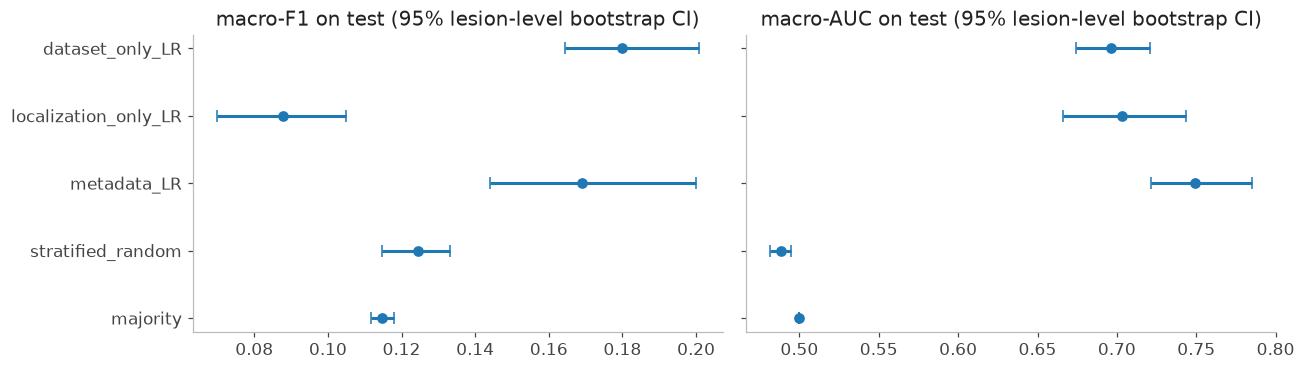

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, i in zip(axes, (0, 2), strict=True):
    values = np.array([point[n][i] for n in MODELS])
    err = [values - [low[n][i] for n in MODELS], [high[n][i] for n in MODELS] - values]
    ax.errorbar(values, range(len(MODELS)), xerr=err, fmt="o", capsize=4)
    ax.set_yticks(range(len(MODELS)), list(MODELS))
    ax.set_title(f"{METRICS[i]} on test (95% lesion-level bootstrap CI)")
plt.tight_layout()
plt.show()

## 5. Conclusions

**Split and integrity**
- 10,015 images, 7,470 lesions, no duplicated `image_id`, no lesion with conflicting diagnoses, 57 images without age.
- The lesion-level split resulted in 8,584 training images and 1,431 test images. No lesion appears in both sets or in multiple folds. Since HAM10000 does not provide patient IDs, different lesions from the same patient may still be present in different sets.

**Class balance**
- The dataset is strongly imbalanced, with `nv` making up 67% of all images. The imbalance is 58:1 per image and 74:1 per lesion. Higher per lesion because `nv` has fewer images per lesion than `mel`.
- The test set contains only 11 `df` and 14 `vasc` lesions, so per-class results for these classes are very uncertain.

**Metadata**
- Age showed the strongest association with the diagnosis (epsilon-squared = 0.21): `nv` is young (median 45), `akiec`, `bcc` and `bkl` are old (median 65-70). `df` and `vasc` are not separable by age.
- Localization had a smaller association with the class (V = 0.22), while sex had almost no association (V = 0.06).
- `dx_type` is tied to the label (V = 0.43): `follow_up` occurs only in `nv`, and `akiec`, `bcc` and `mel` are all histopathology.
- `dataset` was more strongly related to the diagnosis (V = 0.37) and should therefore not be used as a model input.

**Train vs test shift**
- No important difference was found between the training and test sets. All p-values were above 0.15 and the age SMD was -0.03. This is consistent with the lesion-level stratified split.

**Baselines**
- `majority` macro-F1 = 0.115 and `stratified_random` = 0.124; macro-AUC of both is about 0.5. This is the floor for the image models.
- `metadata_LR` reaches macro-F1 = 0.169 and macro-AUC = 0.749, so age, sex and localization together carry real signal without looking at the image.
- `dataset_only_LR` macro-AUC = 0.696, `localization_only_LR` macro-AUC = 0.703